# Lecture 10: the Bell circuit in Qiskit
ECSE 4969/6969 Quantum Information Processing, Fall 2026

Run the cells **in order**, top to bottom. Click a cell, then press the play button at its left (or Shift+Enter). Each cell's output appears directly under it.

Cells 1 and 2 are the setup check you were asked to run before class. Cells 3 to 7 are what we do together. Cell 8 is optional.

## Cell 1. Install Qiskit into this session
The leading `!` means this line is a command for the computer, not Python. It fetches three packages: `qiskit` (the library), `qiskit-aer` (the simulator), and `pylatexenc` (needed to draw circuits). Colab forgets this when the notebook restarts, so run it once per session. It takes about a minute.

In [1]:
!pip install -q qiskit qiskit-aer pylatexenc


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## Cell 2. Check that it works
This should print a version number (for example `2.5.2`; a different number is fine) and draw a one-gate circuit. If the number prints but the drawing fails, the usual cause is that `pylatexenc` did not install: run cell 1 again. If the `import` line itself fails, cell 1 was not run in this session.

2.6.1


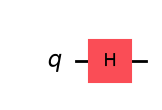

In [2]:
import qiskit
print(qiskit.__version__)
from qiskit import QuantumCircuit
qc = QuantumCircuit(1)
qc.h(0)
qc.draw("mpl")

## Cell 3. Type the Bell circuit in
This is the circuit from Lecture 9: $H$ on qubit $A$, then a CNOT with $A$ as control and $B$ as target. Qiskit numbers wires from 0, top to bottom, so wire 0 is $A$ and wire 1 is $B$. Every wire starts in $|0\rangle$. The last line draws the circuit back so we can check it against the diagram from class.

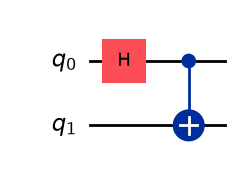

In [3]:
bell = QuantumCircuit(2)      # two wires, both |0>
bell.h(0)                     # H on wire 0 (qubit A)
bell.cx(0, 1)                 # CNOT: wire 0 controls wire 1
bell.draw("mpl")

## Cell 4. First way to see what the circuit does: print its exact state
`Statevector.from_instruction` takes the circuit and returns the state it produces: four amplitudes, printed rounded. No measurement has happened and there is no randomness in this. Only a simulator can print this; a real device cannot.

**Bit order.** Qiskit writes its labels as $|q_1 q_0\rangle$, with wire 0 on the *right*. With $A$ = wire 0 and $B$ = wire 1, Qiskit's order is $BA$, the reverse of our $AB$. The four positions are therefore $|00\rangle, |01\rangle, |10\rangle, |11\rangle$ **in Qiskit's $BA$ order**. For the Bell state this makes no visible difference, because its nonzero terms are $00$ and $11$ and those read the same both ways.

In [4]:
from qiskit.quantum_info import Statevector
sv = Statevector.from_instruction(bell)
print(sv)
print({str(k): round(float(v), 3) for k, v in sv.probabilities_dict().items()})

Statevector([0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.70710678+0.j],
            dims=(2, 2))
{'00': 0.5, '11': 0.5}


### Cell 4b. Bit order made visible
Put $X$ on qubit $A$ alone. In class we write the result $|1\rangle_A |0\rangle_B = |10\rangle_{AB}$. Qiskit prints the nonzero amplitude at position `01`, because its label order is $BA$.

In [5]:
x_on_A = QuantumCircuit(2)
x_on_A.x(0)                   # X on wire 0 = qubit A
sv_x = Statevector.from_instruction(x_on_A)
print({str(k): round(float(v), 3) for k, v in sv_x.probabilities_dict().items()})

{'01': 1.0}


## Cell 5. Second way: run it many times and count
Now we build the same circuit again with two ordinary bits attached to hold the readings (the second `2` in `QuantumCircuit(2, 2)`), add measurements, and hand it to the simulator.

- `measure([0, 1], [0, 1])` measures wire 0 and stores its 0/1 outcome in bit 0, and the same for wire 1. A measurement stores an outcome; it does not copy the state.
- `transpile` translates the circuit into the instructions the chosen simulator supports. Nothing to study in it yet.
- `shots=1024` runs the whole circuit 1024 times.

**Predict before you run this cell:** which of 00, 01, 10, 11 can appear, and in what proportion?

{'00': 506, '11': 518}


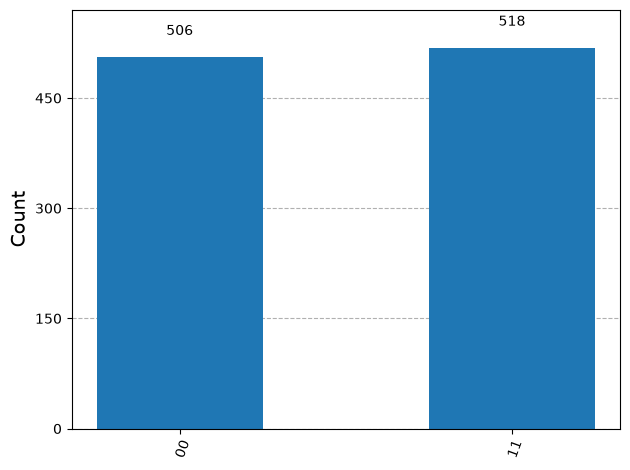

In [6]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

bell_z = QuantumCircuit(2, 2)     # 2 qubits, 2 result bits
bell_z.h(0)
bell_z.cx(0, 1)
bell_z.measure([0, 1], [0, 1])    # read wire 0 into bit 0, wire 1 into bit 1

sim = AerSimulator()
counts_z = sim.run(transpile(bell_z, sim), shots=1024).result().get_counts()
print(counts_z)
plot_histogram(counts_z)

Only `00` and `11` appear, because the state has zero amplitude on `01` and `10`. The two counts are near 512 each but not exactly, because each shot is a random draw; a different run gives different numbers.

## Cell 6. What this tally does not show
The tally matched our prediction for readings in the $Z$ basis. It does **not** by itself establish entanglement. Lecture 8's coin-flip source, which sends $|00\rangle$ or $|11\rangle$ at random, has the same predicted probabilities, so it gives the same kind of tally.

To tell them apart we read the pair in the $X$ basis, the $+/-$ basis from Lecture 6. Qiskit's measurement instruction always records a $Z$-basis outcome, 0 or 1. Applying $H$ first, since $H|+\rangle = |0\rangle$ and $H|-\rangle = |1\rangle$, makes the complete procedure a $+/-$-basis measurement. We interpret a recorded `0` as outcome $+$ and a recorded `1` as outcome $-$.

This is a **new circuit**, `bell_x`, with the two $H$ gates placed *before* the measurements.

**Predict before you run:** for the Bell pair, what should the $X$-basis tally look like?

{'11': 513, '00': 511}


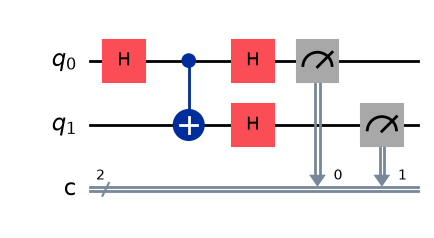

In [7]:
bell_x = QuantumCircuit(2, 2)
bell_x.h(0)
bell_x.cx(0, 1)
bell_x.h(0)                       # H on both wires, just before measuring
bell_x.h(1)
bell_x.measure([0, 1], [0, 1])

counts_x = sim.run(transpile(bell_x, sim), shots=1024).result().get_counts()
print(counts_x)
bell_x.draw("mpl")

## Cell 7. The coin-flip source in the $X$ basis (supplied comparison)
Half the shots come from $|00\rangle$ and half from $|11\rangle$, each read in the $X$ basis. We simulate that with two circuits of 512 shots each and add the tallies.

{'00': 275, '01': 260, '10': 237, '11': 252}


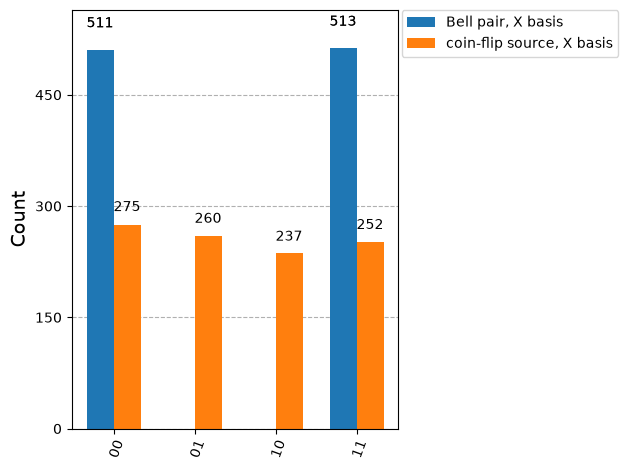

In [8]:
from_00 = QuantumCircuit(2, 2)
from_00.h(0); from_00.h(1)
from_00.measure([0, 1], [0, 1])

from_11 = QuantumCircuit(2, 2)
from_11.x(0); from_11.x(1)        # prepare |11>
from_11.h(0); from_11.h(1)
from_11.measure([0, 1], [0, 1])

c0 = sim.run(transpile(from_00, sim), shots=512).result().get_counts()
c1 = sim.run(transpile(from_11, sim), shots=512).result().get_counts()
counts_mix = {k: c0.get(k, 0) + c1.get(k, 0) for k in ["00", "01", "10", "11"]}
print(counts_mix)
plot_histogram([counts_x, counts_mix], legend=["Bell pair, X basis", "coin-flip source, X basis"])

The Bell pair stays perfectly correlated in the $X$ basis: `00` and `11` only. The coin-flip source spreads over all four outcomes. The first tally matched a prediction; this second one *distinguished* our state from the classical story that also matched the first.

## Cell 8 (optional). Try your own
Change the circuit: replace `h(0)` with `x(0)`, or remove the CNOT, and predict the tally before you run. Then check with the exact state.

In [9]:
mine = QuantumCircuit(2, 2)
mine.h(0)
mine.cx(0, 1)
# edit the lines above, then run
mine.measure([0, 1], [0, 1])
print(sim.run(transpile(mine, sim), shots=1024).result().get_counts())

{'11': 509, '00': 515}
